In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 4)

print("Week 4 - z-Transform Laboratory")

Week 4 - z-Transform Laboratory


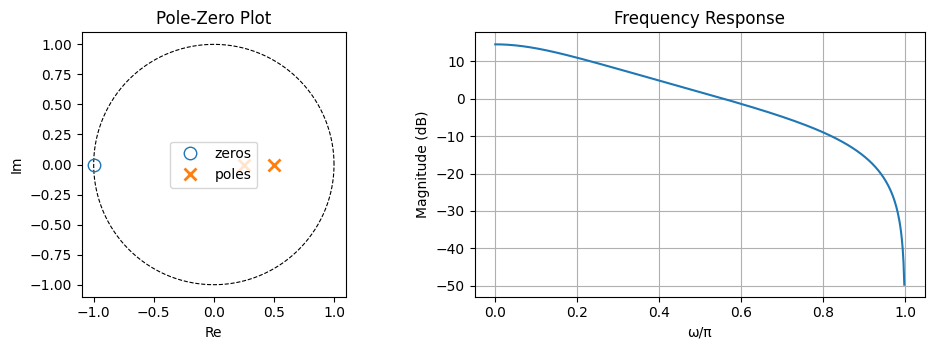

Zeros: [-1.]
Poles: [0.5  0.25]
Stable: True


In [3]:
# TASK 4.1: A Pole-Zero Plotting Function

def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    # Draw the unit circle
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)

    # Plot zeros and poles
    ax.plot(z.real, z.imag, "o", mfc="none",
            ms=9, label="zeros")

    ax.plot(p.real, p.imag, "x", ms=9,
            mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title("Pole-Zero Plot")

    return z, p


# Define the transfer function
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

# Pole-zero diagram
z, p = zplane(b, a, ax1)

# Frequency response
w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.maximum(np.abs(H), 1e-10)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid()

plt.tight_layout()
plt.show()

# Check stability
print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

In [4]:
np.all(np.abs(p) < 1)

np.True_

The task successfully demonstrated how to identify poles and zeros using Python. The zplane() function plotted the pole-zero diagram, while signal.freqz() displayed the frequency response. The stability test confirmed that the system is stable because all its poles lie inside the unit circle.

In [5]:
# TASK 4.2: Inverse z-transform using residuez

r, p, k = signal.residuez(
    [1],
    [1, -0.75, 0.125]
)

print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []


In [6]:
# Calculate inverse z-transform using partial fractions

n = np.arange(10)

x_pf = sum(
    ri * pi**n for ri, pi in zip(r, p)
).real

print("Inverse z-transform:")
print(x_pf)

Inverse z-transform:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]


In [7]:
# Verify using lfilter

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(
    [1],
    [1, -0.75, 0.125],
    impulse
)

print("lfilter output:")
print(x_lf)

print("Both methods give the same result:",
      np.allclose(x_pf, x_lf))

lfilter output:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Both methods give the same result: True


In [8]:
# Repeat Task 4.2 using Task 4.1 system

b = [1, 1]
a = [1, -0.75, 0.125]

# Calculate residues and poles
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)

# Calculate impulse response using partial fractions
n = np.arange(10)

h_pf = sum(
    ri * pi**n for ri, pi in zip(r, p)
).real

print("Impulse response using residuez:")
print(h_pf)

# Verify using lfilter
impulse = np.zeros(10)
impulse[0] = 1

h_lf = signal.lfilter(b, a, impulse)

print("Impulse response using lfilter:")
print(h_lf)

print("Results match:", np.allclose(h_pf, h_lf))

Residues: [-5.  6.]
Poles: [0.25 0.5 ]
Impulse response using residuez:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


In [9]:
# Theoretical impulse response

h_theory = 6*(0.5)**n - 5*(0.25)**n

print("Theoretical response:")
print(h_theory)

print("Matches residuez:",
      np.allclose(h_pf, h_theory))

Theoretical response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Matches residuez: True


This successfully demonstrated the use of the residuez() function to calculate the inverse z-transform. The results were verified using lfilter() and the theoretical expression. Both methods produced matching results.

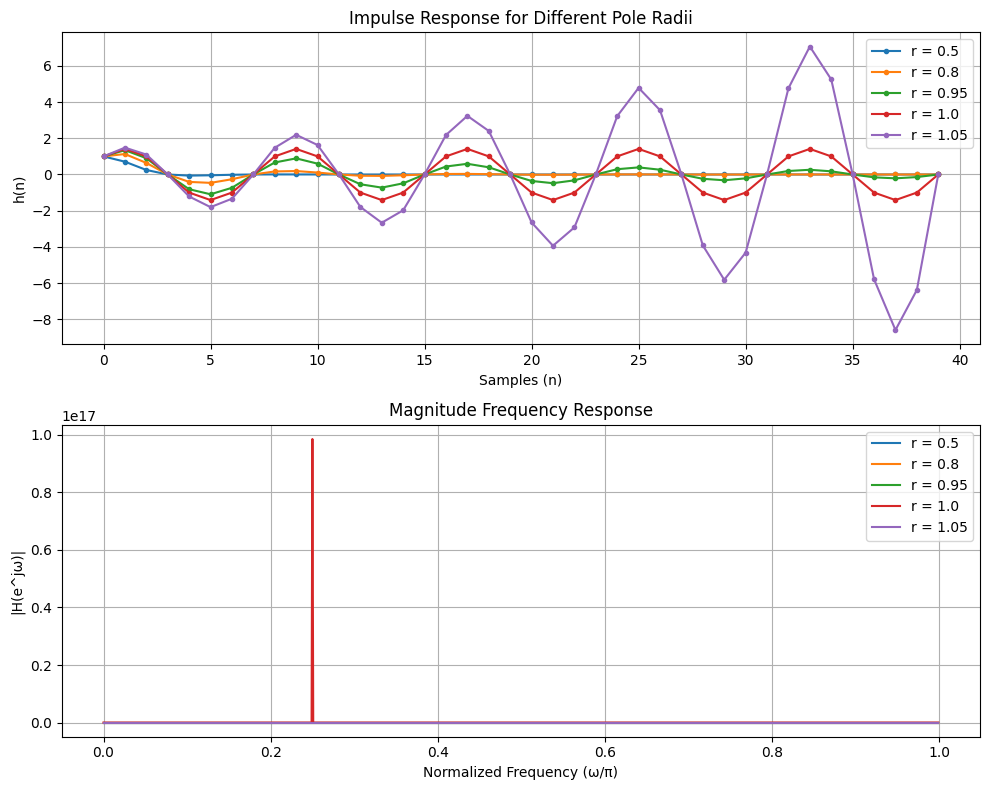

In [10]:
# TASK 4.3: Pole Position and the Impulse Response

r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

N = 40
impulse = np.zeros(N)
impulse[0] = 1

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

for r in r_values:

    # Denominator coefficients
    a = [1, -2*r*np.cos(np.pi/4), r**2]

    # Calculate impulse response
    h = signal.lfilter([1], a, impulse)

    # Plot impulse response
    ax1.plot(np.arange(N), h, marker="o",
             markersize=3, label=f"r = {r}")

    # Calculate frequency response
    w, H = signal.freqz([1], a, worN=1024)

    # Plot magnitude response
    ax2.plot(w/np.pi, np.abs(H),
             label=f"r = {r}")

# Impulse response graph
ax1.set_title("Impulse Response for Different Pole Radii")
ax1.set_xlabel("Samples (n)")
ax1.set_ylabel("h(n)")
ax1.legend()
ax1.grid()

# Frequency response graph
ax2.set_title("Magnitude Frequency Response")
ax2.set_xlabel("Normalized Frequency (ω/π)")
ax2.set_ylabel("|H(e^jω)|")
ax2.legend()
ax2.grid()

plt.tight_layout()
plt.show()

The results show that the pole radius has a significant effect on the behaviour and stability of a system. A smaller pole radius causes the impulse response to decay faster, while a larger radius causes the oscillations to last longer.

When the pole radius reaches one, the system has poles on the unit circle, resulting in a resonance peak. When the radius exceeds one, the impulse response grows with time, indicating instability.

H1 (a)
Poles: [0.8+0.5j 0.8-0.5j]
Stable: True
--------------------------------
H2 (b)
Poles: [2.  0.5]
Stable: False
--------------------------------
H3 (c)
Poles: [-1.   0.5]
Stable: False
--------------------------------
H4 (d)
Poles: []
Stable: True
--------------------------------


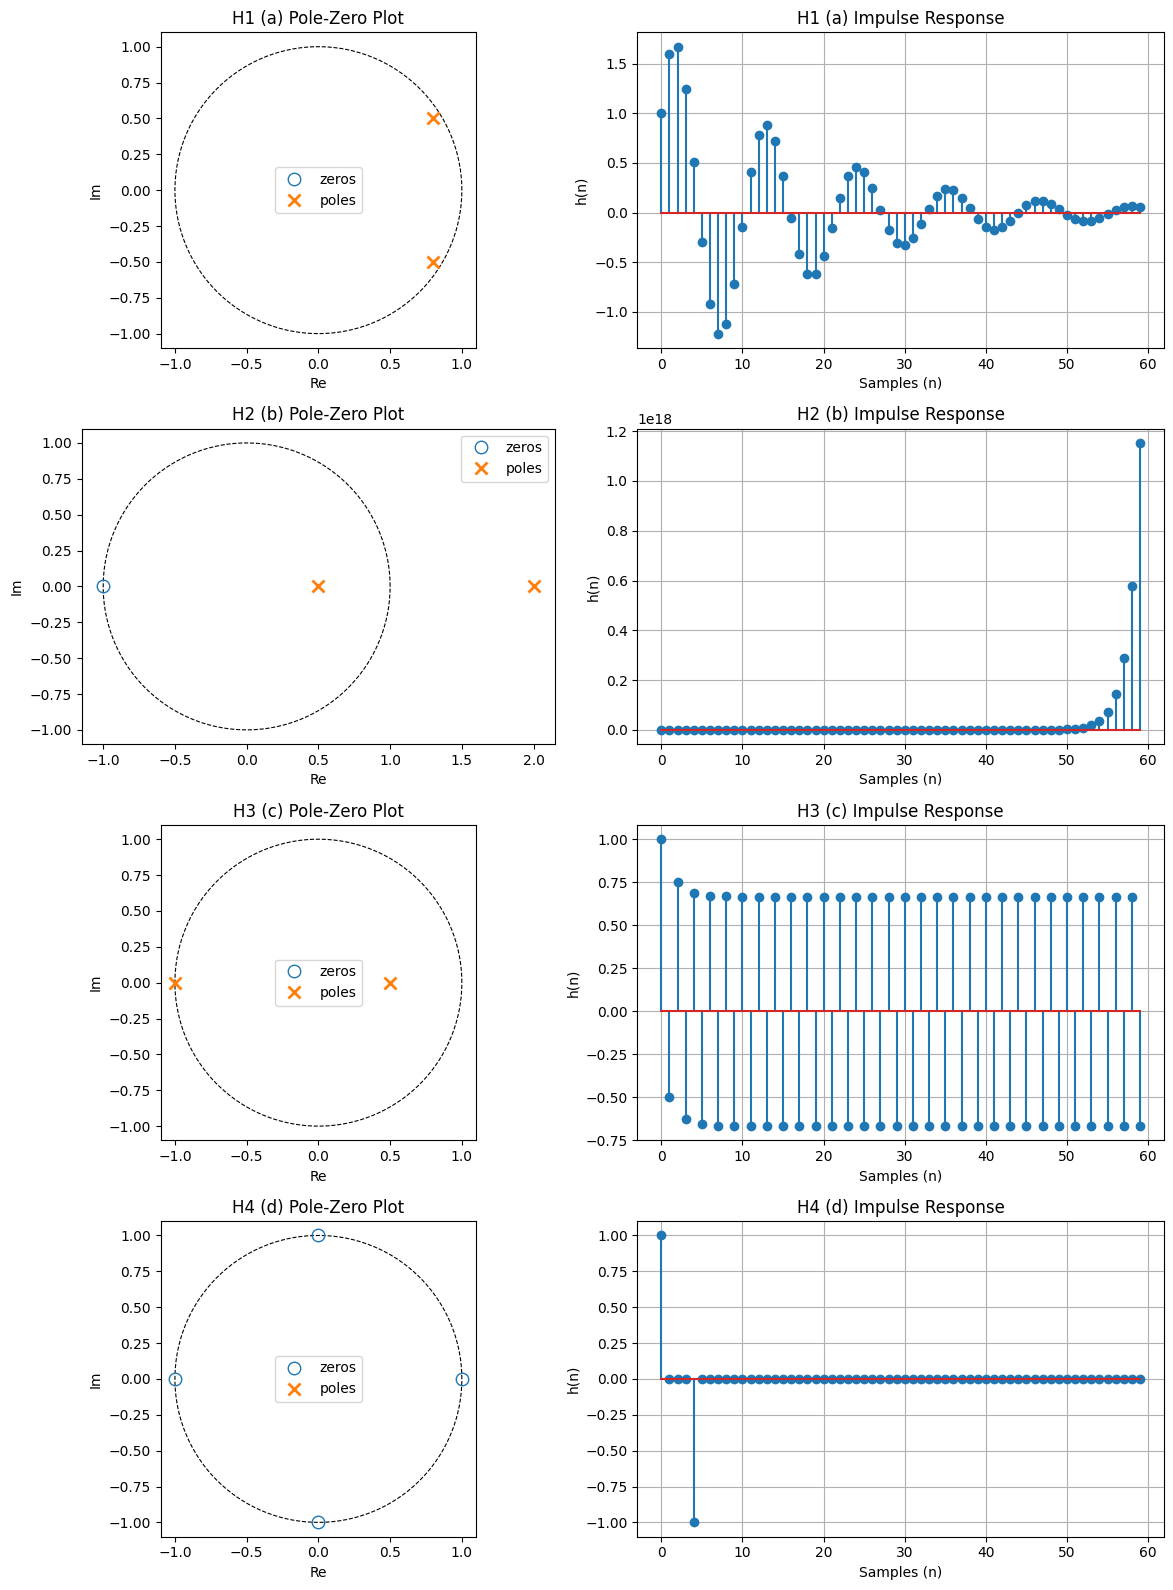

In [11]:
# TASK 4.4: Stability of Given Systems

systems = {
    "H1 (a)": ([1], [1, -1.6, 0.89]),
    "H2 (b)": ([1, 1], [1, -2.5, 1]),
    "H3 (c)": ([1], [1, 0.5, -0.5]),
    "H4 (d)": ([1, 0, 0, 0, -1], [1])
}

N = 60
impulse = np.zeros(N)
impulse[0] = 1

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, (name, (b, a)) in enumerate(systems.items()):

    # Find poles and zeros
    z, p = zplane(b, a, axes[i, 0])

    axes[i, 0].set_title(name + " Pole-Zero Plot")

    # Check stability
    stable = np.all(np.abs(p) < 1)

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    axes[i, 1].stem(np.arange(N), h)
    axes[i, 1].set_title(name + " Impulse Response")
    axes[i, 1].set_xlabel("Samples (n)")
    axes[i, 1].set_ylabel("h(n)")
    axes[i, 1].grid()

    print(name)
    print("Poles:", p)
    print("Stable:", stable)
    print("--------------------------------")

plt.tight_layout()
plt.show()

This demonstrates how to determine the stability of discrete-time systems using pole-zero diagrams and impulse responses. The results showed that H1 and H4 are stable, while H2 and H3 are unstable.

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]


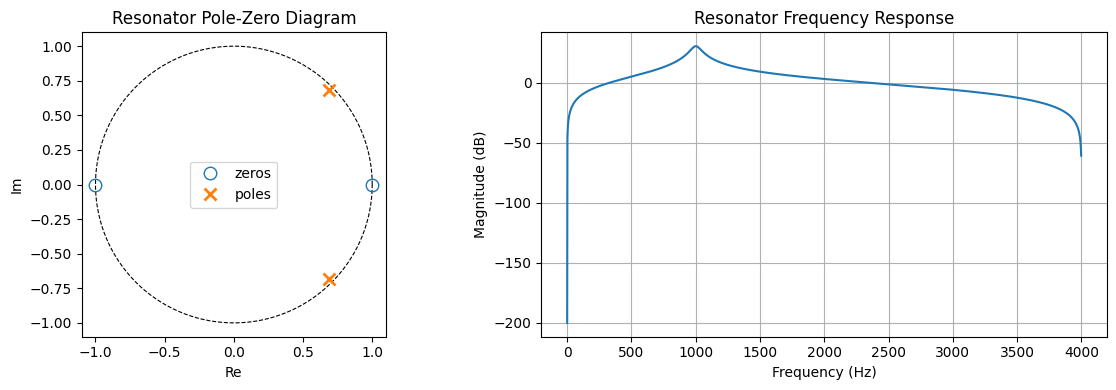

Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Zeros: [-1.  1.]
Stable: True


In [12]:
# TASK 4.5: Design a Resonator

from IPython.display import Audio, display

# Design specifications
fs = 8000
f0 = 1000
r = 0.97

# Calculate resonance angle
theta = 2*np.pi*f0/fs

# Numerator: zeros at z = +1 and z = -1
b = [1, 0, -1]

# Denominator: poles at r*exp(+/-j*theta)
a = [1, -2*r*np.cos(theta), r**2]

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

# Plot pole-zero diagram and frequency response
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

z, p = zplane(b, a, ax1)
ax1.set_title("Resonator Pole-Zero Diagram")

# Frequency response in Hz
w, H = signal.freqz(b, a, worN=2048, fs=fs)

ax2.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-10)))
ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

print("Poles:", p)
print("Zeros:", z)
print("Stable:", np.all(np.abs(p) < 1))

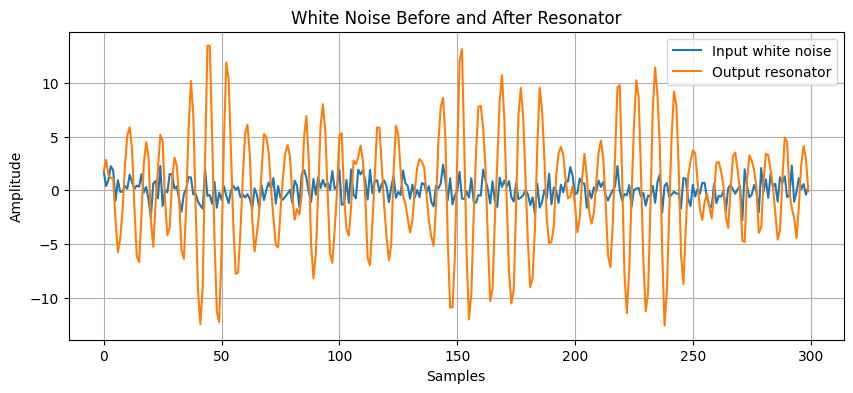

In [13]:
# Generate white noise
np.random.seed(0)

x = np.random.randn(8000)

# Apply resonator
y = signal.lfilter(b, a, x)

# Plot input and output signals
plt.figure(figsize=(10, 4))

plt.plot(x[:300], label="Input white noise")
plt.plot(y[:300], label="Output resonator")

plt.title("White Noise Before and After Resonator")
plt.xlabel("Samples")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# Listen to the output
display(Audio(y, rate=8000))

The results show that the resonator emphasizes the frequency components around 1 kHz. The output signal has larger oscillations because the resonator amplifies frequencies near its resonance frequency. This demonstrates how a resonator can select and emphasize a particular frequency from white noise.

# COU07506 - Digital Signal Processing
# WEEK 4: z-Transform Laboratory: Poles, Zeros and Stability

# Student Name: Swaum Hussen Idd
# Registration Number: 240242406676
# Institution: Dar es Salaam Institute of Technology (DIT)

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 4)

print("Week 4 - z-Transform Laboratory")